In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal
from scipy import stats



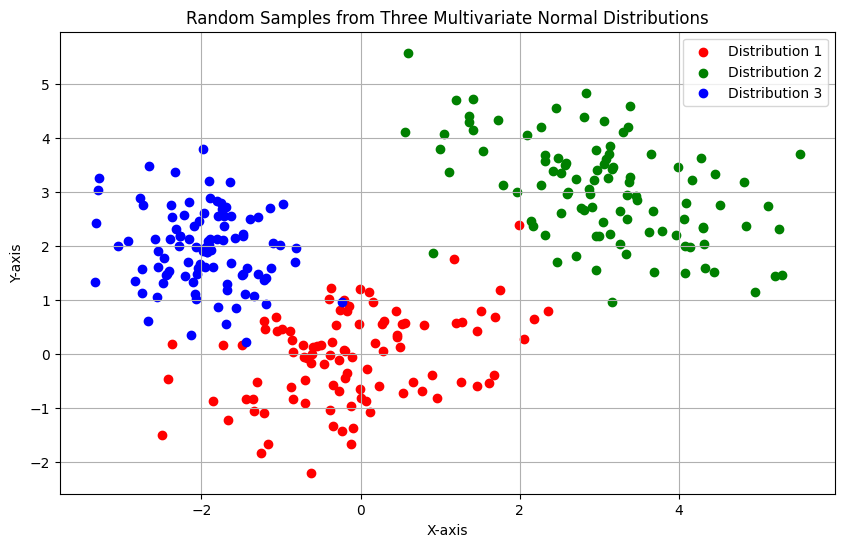

In [ ]:
# Parameters for the multivariate normal distributions
mean1 = [0, 0]
cov1 = [[1, 0.5], [0.5, 1]]
mean2 = [3, 3]
cov2 = [[1, -0.5], [-0.5, 1]]
mean3 = [-2, 2]
cov3 = [[0.5, 0], [0, 0.5]]

# Sample data points from each distribution
data1 = np.random.multivariate_normal(mean1, cov1, 100)
data2 = np.random.multivariate_normal(mean2, cov2, 100)
data3 = np.random.multivariate_normal(mean3, cov3, 100)

# Plotting the data points
plt.figure(figsize=(10, 6))
plt.scatter(data1[:, 0], data1[:, 1], color='red', label='Distribution 1')
plt.scatter(data2[:, 0], data2[:, 1], color='green', label='Distribution 2')
plt.scatter(data3[:, 0], data3[:, 1], color='blue', label='Distribution 3')
plt.title('Random Samples from Three Multivariate Normal Distributions')
plt.xlabel('X-axis')
plt.ylabel('Y-axis')
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
def GMM(X, init_means, init_covs, init_mix_props, thres=0.001):
    means = init_means
    covs = init_covs
    mix_props = init_mix_props
    ll_old = 0
    ll_list = []

    while True:
        # E-step: Calculate the hidden matrix and log-likelihood
        hidden_matrix, ll_new = HiddenMatrix(X, means, covs, mix_props)
        ll_list.append(ll_new)

        # Check for convergence
        if np.abs(ll_new - ll_old) < thres:
            break
        ll_old = ll_new

        # M-step: Update parameters
        mix_props = UpdateMixProps(hidden_matrix)
        means = UpdateMeans(X, hidden_matrix)
        covs = UpdateCovars(X, hidden_matrix, means)

    clusters = np.argmax(hidden_matrix, axis=1)
    return clusters, hidden_matrix, ll_list

def UpdateMixProps(hidden_matrix):
    mix_props = np.sum(hidden_matrix, axis=0) / hidden_matrix.shape[0]
    return mix_props

def UpdateMeans(X, hidden_matrix):
    n,d = X.shape
    k = hidden_matrix.shape[1]
    new_means = np.zeros([k,d])
    # begin solution
    for i in range(k):
        new_means[i, :] = (X.T * hidden_matrix[:, i]).T.sum(axis=0) / hidden_matrix[:, i].sum()
    # end solution
    return new_means

def UpdateCovars(X, hidden_matrix, means):
    n,d = X.shape
    k = hidden_matrix.shape[1]
    new_covs = np.zeros([k,d,d])
    # begin solution
    for i in range(k):
        temp_mat = np.zeros([d,d])
        for j in range(n):
            temp_mat += np.outer(X[j] - means[i], X[j] - means[i]) * hidden_matrix[j, i]
        new_covs[i, :, :] = temp_mat / hidden_matrix[:, i].sum()
    # end solution
    return new_covs

def HiddenMatrix(X, means, covs, mix_props):
    n,d = X.shape
    k = means.shape[0]
    hidden_matrix = np.zeros([n,k])
    ll = 0
    t = np.zeros([n,k]) # intermediate matrix
    # begin solution
    for i in range(n):
        for j in range(k):
            t[i,j] = MultiVarNormal(X[i], means[j], covs[j]) * mix_props[j]
    ll = np.sum(np.log(np.sum(t, axis=1)))
    hidden_matrix = (t.T / t.sum(axis=1)).T
    # end solution
    return hidden_matrix, ll

In [ ]:
# Now let's check your implementations
def print_msg(abs_dif, fct_name=''):
    if abs_dif < 1e-6:
        print('Checking %s: \t pass, abs_dif=%0.5e' % (fct_name, abs_dif))
    else:
        print('Checking %s: \t fail, abs_dif=%0.5e' % (fct_name, abs_dif))

# MultiVarNormal
x = np.array([1,2])
mean = np.array([0,1])
cov = np.eye(2)
myres = MultiVarNormal(x,mean,cov)
truth = stats.multivariate_normal.pdf(x, mean, cov)
print_msg(myres-truth, fct_name='MultiVarNormal')

# Data
hidden_matrix = np.array([[0.4, 0.6], [0.8, 0.2], [0.2, 0.8]]) # 3 data points and 2 clusters
data = np.array([[1, 0, 2], [0, 1, 0], [3, 2, 1]]) # 3 data points and 3 features

# UpdateMixProps
mix_props = UpdateMixProps(hidden_matrix)
abs_dif = np.abs(mix_props[0] - 0.46666667).sum()
print_msg(abs_dif, fct_name='UpdateMixProps')

# UpdateMeans
new_means = UpdateMeans(data, hidden_matrix)
abs_dif = np.abs(new_means[0] - np.array([0.71428571, 0.85714286, 0.71428571])).sum()
print_msg(abs_dif, fct_name='UpdateMeans')

# UpdateCovars
new_covs = UpdateCovars(data, hidden_matrix, new_means)
abs_dif = np.abs(new_covs[0][0] - np.array([1.06122449, 0.24489796, 0.48979592])).sum()
print_msg(abs_dif, fct_name='UpdateCovars')

# HiddenMatrix
hidden_matrix,ll = HiddenMatrix(data, new_means, new_covs, mix_props)
abs_dif = np.abs(hidden_matrix[0] - np.array([0.44987172, 0.55012828])).sum()
print_msg(abs_dif, fct_name='HiddenMatrix')

Checking MultiVarNormal: 	 pass, abs_dif=0.00000e+00
Checking UpdateMixProps: 	 pass, abs_dif=3.33333e-09
Checking UpdateMeans: 	 pass, abs_dif=1.14286e-08
Checking UpdateCovars: 	 pass, abs_dif=2.65306e-09


LinAlgError: When `allow_singular is False`, the input matrix must be symmetric positive definite.